# 03 · Evaluate the Models and Select the Best
**RedactNER: Local PII Redaction for Word Documents**

This notebook compares the fine-tuned encoders with each other and with two off-the-shelf systems,
selects the best model, tunes its decision thresholds per category and exports it for the application.

| System | Kind |
|---|---|
| RoBERTa-base, DeBERTa-v3-base, ModernBERT-base | Fine-tuned in notebook 02, two seeds each |
| ModernBERT-large | Fine-tuned in notebook 02, one seed (scale experiment) |
| ModernBERT-base (Prototype) | The first checkpoint, trained on a smaller set without Gretel or augmentation |
| GLiNER-PII (`nvidia/gliner-PII`) | Off-the-shelf zero-shot PII extractor built on DeBERTa-v3-large |
| spaCy `en_core_web_trf` | Off-the-shelf general-purpose named entity recogniser |

| Test Set | Purpose |
|---|---|
| Nemotron-PII | In-domain, document-style synthetic PII |
| ai4privacy OpenPII | In-domain, short synthetic texts |
| Gretel Finance | In-domain, long synthetic financial documents |
| TAB | Real court judgments annotated by legal experts, never used for training or tuning |

GLiNER-PII was trained on Nemotron-PII, so that test set is in-domain for it as well.

All metrics are computed on character spans, so they do not depend on any tokenizer.
* **Character-Level Precision, Recall and F5.** Label-agnostic scores that measure whether the right
  text was redacted. F5 weights recall five times as heavily as precision, because a missed identifier is
  a privacy breach while an extra redaction only reduces readability.
* **Leak Rate.** The share of gold mentions with at least one letter or digit left visible. It is reported
  over all categories and over *direct identifiers* (names, contact details, street addresses, ID and
  financial numbers, usernames, credentials, IP addresses and URLs), which identify a person on their own.
* **Entity F1.** Typed, strict scores that require exact boundaries and the correct category.
* **TAB Scores.** The benchmark's own entity-level recall for direct and quasi-identifiers (an entity counts
  as protected only when all of its mentions are masked) and word-level precision against the annotators.
  Every TAB score is averaged over the annotators of each document and, as in the official script, titles
  such as *Mr*, function words and punctuation inside a mention do not have to be masked.

The decision threshold τ (a token is tagged as PII when P(O) < τ) is tuned on the development set for every
model, and the best architecture is chosen on the development set before any test set is scored.

In [1]:
RUNS = {
    "RoBERTa-base": ["roberta-base_s42", "roberta-base_s7"],
    "DeBERTa-v3-base": ["deberta-v3-base_s42", "deberta-v3-base_s7"],
    "ModernBERT-base": ["modernbert-base_s42", "modernbert-base_s7"],
    "ModernBERT-large": ["modernbert-large_s42"],
}
REFERENCE = {"ModernBERT-base (Prototype)": "modernbert-base_prototype"}
TEST_SETS = ["test_nemotron", "test_ai4privacy", "test_gretel", "test_tab"]
TAU_GRID = [0.5, 0.7, 0.8, 0.9, 0.95, 0.97, 0.98, 0.99, 0.995, 0.998, 0.999]
MIN_PRECISION = 0.80   # minimum development character precision for an operating point
BETA = 5               # recall weight for direct identifiers (and for model selection)
QUASI_BETA = 2         # recall weight for quasi-identifiers when thresholds are tuned per category
QUASI_LABELS = ["LOCATION", "DATE", "ORGANIZATION"]
GLINER_GRID = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
RUN_BASELINES = True
SMOKE = False          # quick check on a few documents; writes to separate *_smoke folders
PROJECT_DIR = ".."

## 0. Setup
This notebook uses the project package in `src/redactner`. The off-the-shelf baselines need the optional
`experiments` dependency group (`uv sync --group experiments`). On Google Colab, clone the repository and
run `pip install -e . gliner spacy spacy-curated-transformers` and the spaCy model download first.

In [2]:
import json
import shutil
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import AutoModelForTokenClassification, AutoTokenizer

ROOT = Path(PROJECT_DIR).resolve()
sys.path.insert(0, str(ROOT / "src"))
from redactner.baselines import save_predictions  # noqa: E402
from redactner.inference import META_FILE, TokenClassifierDetector  # noqa: E402
from redactner.labels import LABELS  # noqa: E402
from redactner.metrics import CorpusScorer, TabScorer, tab_ignored_chars  # noqa: E402
from redactner.thresholds import TokenTable, tune_global, tune_per_category  # noqa: E402
from redactner.weights import split_large_files  # noqa: E402

DATA = ROOT / "data" / "processed"
MODELS = ROOT / "models"
SUFFIX = "_smoke" if SMOKE else ""
MAX_DOCS = 20 if SMOKE else None
RESULTS = ROOT / f"results{SUFFIX}"
PREDICTIONS = ROOT / "outputs" / f"predictions{SUFFIX}"
RESULTS.mkdir(parents=True, exist_ok=True)
print("CUDA available:", torch.cuda.is_available())

SET_NAMES = {"dev": "Development", "test_nemotron": "Nemotron-PII", "test_ai4privacy": "ai4privacy OpenPII",
             "test_gretel": "Gretel Finance", "test_tab": "TAB"}
CATEGORY_NAMES = {"PERSON": "Person", "EMAIL": "Email", "PHONE": "Phone", "ADDRESS": "Address",
                  "LOCATION": "Location", "DATE": "Date", "ID_NUMBER": "ID Number", "FINANCIAL": "Financial",
                  "USERNAME": "Username", "CREDENTIAL": "Credential", "IP_ADDRESS": "IP Address", "URL": "URL",
                  "ORGANIZATION": "Organisation"}
METRIC_NAMES = {"tau": "τ", "char_precision": "Char Precision", "char_recall": "Char Recall", "char_f1": "Char F1",
                "char_f5": "Char F5", "leak_rate": "Leak Rate", "direct_leak_rate": "Direct Leak Rate",
                "entity_precision": "Entity Precision", "entity_recall": "Entity Recall", "entity_f1": "Entity F1",
                "er_direct": "ER Direct", "er_quasi": "ER Quasi", "leak_direct": "Direct Mention Leak Rate",
                "leak_quasi": "Quasi Mention Leak Rate", "word_precision": "Word Precision"}
missing = [run for runs in RUNS.values() for run in runs if not (MODELS / run / "config.json").exists()]
if missing:
    print("Checkpoints not found, skipped:", ", ".join(missing))
RUNS = {arch: [r for r in runs if r not in missing] for arch, runs in RUNS.items()}
RUNS = {arch: runs for arch, runs in RUNS.items() if runs}
ARCH_OF = {run: arch for arch, runs in RUNS.items() for run in runs}
ARCH_OF.update({run: name for name, run in REFERENCE.items() if (MODELS / run / "config.json").exists()})


def run_name(run):
    seed = run.rsplit("_s", 1)[-1]
    if run in REFERENCE.values() or not seed.isdigit():
        return ARCH_OF[run]
    return f"{ARCH_OF[run]} (Seed {seed})"


def read_jsonl(path):
    with open(path, encoding="utf-8") as fh:
        docs = [json.loads(line) for line in fh]
    return docs[:MAX_DOCS] if MAX_DOCS else docs


sets = {name: read_jsonl(DATA / f"{name}.jsonl") for name in ["dev"] + TEST_SETS}
print("Documents per set:", ", ".join(f"{SET_NAMES[k]} {len(v):,}" for k, v in sets.items()))

CUDA available: True


Documents per set: Development 2,750, Nemotron-PII 1,000, ai4privacy OpenPII 1,000, Gretel Finance 1,000, TAB 127


## 1. Token Probabilities
Every model reads every document once; the token probabilities are cached and decoded under different
thresholds afterwards. Inference speed is measured on the Nemotron-PII test set.

In [3]:
detectors, probs, latency = {}, {}, {}
for run in ARCH_OF:
    det = TokenClassifierDetector(MODELS / run)
    for name, docs in sets.items():
        t0 = time.perf_counter()
        probs[(run, name)] = [det.token_probs(d["text"]) for d in docs]
        elapsed = time.perf_counter() - t0
        if name == "test_nemotron":
            n_chars = sum(len(d["text"]) for d in docs)
            latency[run] = {"ms_per_doc": 1000 * elapsed / len(docs), "ms_per_1k_chars": 1e6 * elapsed / n_chars}
    det.model = None  # the label layout is all that decoding needs
    detectors[run] = det
    torch.cuda.empty_cache()
    print(f"{run_name(run):<34} {latency[run]['ms_per_doc']:6.1f} ms per document")

RoBERTa-base (Seed 42)                9.1 ms per document


RoBERTa-base (Seed 7)                 9.2 ms per document


DeBERTa-v3-base (Seed 42)            20.9 ms per document


DeBERTa-v3-base (Seed 7)             25.4 ms per document


ModernBERT-base (Seed 42)            19.8 ms per document


ModernBERT-base (Seed 7)             41.6 ms per document


ModernBERT-large (Seed 42)           29.5 ms per document


ModernBERT-base (Prototype)          20.0 ms per document


## 2. Threshold Tuning on the Development Set
Each model receives its own operating point: the threshold with the highest character-level F5, subject to a
minimum character-level precision of 0.80. Because the characters a threshold redacts are exactly those of
the tokens it flags, every candidate threshold is scored directly on the cached token probabilities.

In [4]:
tables = {run: TokenTable.build(detectors[run], sets["dev"], probs[(run, "dev")]) for run in ARCH_OF}
chosen_tau, sweep_rows = {}, []
for run, table in tables.items():
    chosen_tau[run], rows = tune_global(table, TAU_GRID, MIN_PRECISION, BETA)
    sweep_rows += [{"run": run, **r} for r in rows]
    sweep_rows.append({"run": run, "tau": "argmax", **table.scores(table.flags(argmax=True), BETA)})
sweep = pd.DataFrame(sweep_rows)
dev_best = sweep[[t == chosen_tau[r] for r, t in zip(sweep.run, sweep.tau)]].set_index("run")
DEV_COLS = ["tau", "char_precision", "char_recall", "char_f5", "leak_rate", "direct_leak_rate"]


def pretty(df, index_name="Model"):
    out = df.rename(columns=METRIC_NAMES)
    out.index = [run_name(i) if i in ARCH_OF else i for i in out.index]
    out.index.name = index_name
    return out


print("Chosen τ per model:", ", ".join(f"{run_name(r)} {t}" for r, t in chosen_tau.items()))
pretty(dev_best[DEV_COLS].round(4))

Chosen τ per model: RoBERTa-base (Seed 42) 0.97, RoBERTa-base (Seed 7) 0.97, DeBERTa-v3-base (Seed 42) 0.97, DeBERTa-v3-base (Seed 7) 0.97, ModernBERT-base (Seed 42) 0.98, ModernBERT-base (Seed 7) 0.97, ModernBERT-large (Seed 42) 0.98, ModernBERT-base (Prototype) 0.995


,τ,Char Precision,Char Recall,Char F5,Leak Rate,Direct Leak Rate
Model,,,,,,
RoBERTa-base (Seed 42),0.97,0.8923,0.9960,0.9915,0.0060,0.0039
RoBERTa-base (Seed 7),0.97,0.8961,0.9957,0.9914,0.0063,0.0039
DeBERTa-v3-base (Seed 42),0.97,0.8941,0.9962,0.9918,0.0062,0.0040
DeBERTa-v3-base (Seed 7),0.97,0.8932,0.9962,0.9918,0.0060,0.0042
ModernBERT-base (Seed 42),0.98,0.8873,0.9962,0.9916,0.0061,0.0038
ModernBERT-base (Seed 7),0.97,0.9081,0.9948,0.9911,0.0083,0.0049
ModernBERT-large (Seed 42),0.98,0.9014,0.9957,0.9917,0.0068,0.0046
ModernBERT-base (Prototype),0.995,0.8299,0.9681,0.9619,0.0472,0.0113


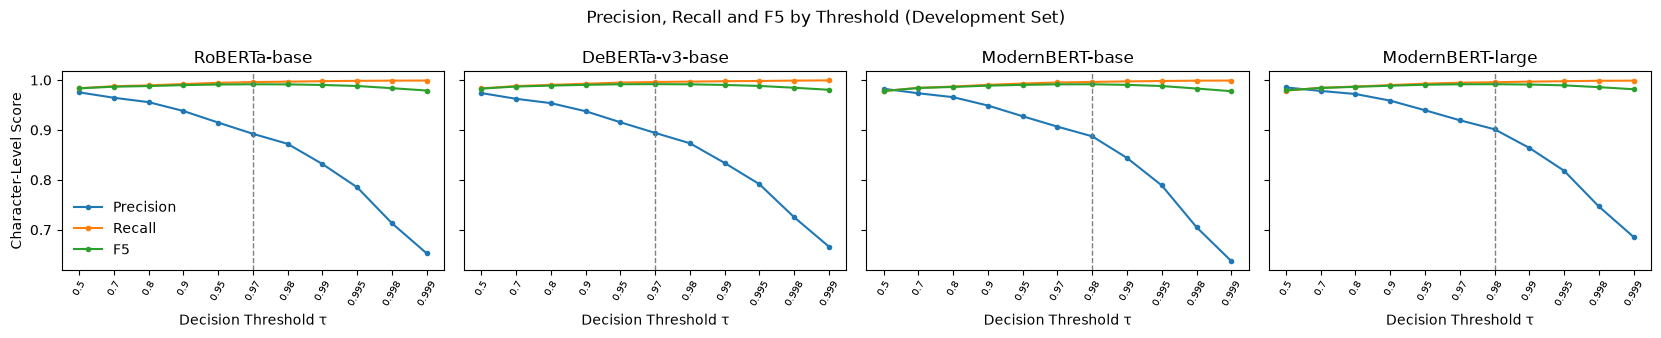

In [5]:
plot_runs = [runs[0] for runs in RUNS.values() if runs[0] in ARCH_OF]
fig, axes = plt.subplots(1, len(plot_runs), figsize=(4.2 * len(plot_runs), 3.4), sharey=True)
for ax, run in zip(np.atleast_1d(axes), plot_runs):
    d = sweep[(sweep.run == run) & (sweep.tau != "argmax")]
    x = np.arange(len(d))
    for col, lab in (("char_precision", "Precision"), ("char_recall", "Recall"), ("char_f5", "F5")):
        ax.plot(x, d[col].astype(float), "o-", label=lab, markersize=3)
    ax.axvline(list(d.tau).index(chosen_tau[run]), color="grey", linestyle="--", linewidth=1)
    ax.set_xticks(x, [str(t) for t in d.tau], rotation=60, fontsize=7)
    ax.set_title(ARCH_OF[run])
    ax.set_xlabel("Decision Threshold τ")
np.atleast_1d(axes)[0].set_ylabel("Character-Level Score")
np.atleast_1d(axes)[0].legend(frameon=False)
fig.suptitle("Precision, Recall and F5 by Threshold (Development Set)")
plt.tight_layout()
plt.savefig(RESULTS / "fig_threshold_sweep.png", dpi=150)
plt.show()

## 3. Model Selection
The architecture with the highest mean development F5 over its seeds is selected, and its best seed is
exported. The prototype checkpoint is shown for reference only.

In [6]:
dev_runs = dev_best[DEV_COLS].copy()
dev_runs["architecture"] = [ARCH_OF[r] for r in dev_runs.index]
candidates = dev_runs[dev_runs.architecture.isin(RUNS)]
arch_dev = candidates.groupby("architecture")[DEV_COLS[1:]].agg(["mean", "std"])
BEST_ARCH = arch_dev[("char_f5", "mean")].idxmax()
BEST = candidates[candidates.architecture == BEST_ARCH]["char_f5"].idxmax()
print(f"Selected architecture: {BEST_ARCH} | exported checkpoint: {run_name(BEST)} (τ = {chosen_tau[BEST]})")


def mean_sd(df, cols, digits=4):
    out = pd.DataFrame(index=df.index)
    for c in cols:
        m, s = df[(c, "mean")], df[(c, "std")]
        out[METRIC_NAMES.get(c, c)] = [f"{a:.{digits}f}" + (f" ± {b:.{digits}f}" if b == b else "")
                                       for a, b in zip(m, s)]
    out.index.name = "Architecture"
    return out


selection_table = mean_sd(arch_dev.sort_values(("char_f5", "mean"), ascending=False), DEV_COLS[1:])
selection_table

Selected architecture: DeBERTa-v3-base | exported checkpoint: DeBERTa-v3-base (Seed 42) (τ = 0.97)


,Char Precision,Char Recall,Char F5,Leak Rate,Direct Leak Rate
Architecture,,,,,
DeBERTa-v3-base,0.8936 ± 0.0006,0.9962 ± 0.0000,0.9918 ± 0.0000,0.0061 ± 0.0002,0.0041 ± 0.0001
ModernBERT-large,0.9014,0.9957,0.9917,0.0068,0.0046
RoBERTa-base,0.8942 ± 0.0027,0.9958 ± 0.0002,0.9915 ± 0.0001,0.0061 ± 0.0003,0.0039 ± 0.0000
ModernBERT-base,0.8977 ± 0.0148,0.9955 ± 0.0010,0.9913 ± 0.0003,0.0072 ± 0.0015,0.0044 ± 0.0008


## 4. Per-Category Thresholds for the Selected Model
A single aggressive threshold over-redacts dates and organisations, which are only quasi-identifiers. The
decision rule therefore generalises to one threshold per category: with a minimum confidence of 1 − τ_c for
category c, a token is redacted when Σ_c P(c) / (1 − τ_c) > 1. This is the Bayes-optimal decision when missing
category c costs τ_c / (1 − τ_c) times as much as an unnecessary redaction, and it reduces to P(O) < τ when all
thresholds are equal. Because the probabilities of all categories are summed, relaxing dates cannot hide a token
that is also likely to be, for example, an ID number.

Direct identifiers keep the global threshold. The thresholds of locations, dates and organisations are relaxed
one at a time to minimise the expected cost on the development set, where a missed character costs β² (25 for
direct identifiers and 4 for quasi-identifiers, matching F5 and F2) and an unnecessary redaction costs 1. The
result is adopted when it raises development precision while neither the overall nor the direct-identifier leak
rate rises by more than 0.1 percentage points.

In [7]:
miss_costs = {lab: (QUASI_BETA if lab in QUASI_LABELS else BETA) ** 2 for lab in LABELS}
category_tau = tune_per_category(tables[BEST], TAU_GRID, miss_costs, chosen_tau[BEST], QUASI_LABELS)
dev_global = tables[BEST].scores(tables[BEST].flags(chosen_tau[BEST]), BETA)
dev_category = tables[BEST].scores(tables[BEST].flags(category_tau), BETA)
USE_CATEGORY_TAU = (dev_category["char_precision"] > dev_global["char_precision"]
                    and dev_category["leak_rate"] <= dev_global["leak_rate"] + 0.001
                    and dev_category["direct_leak_rate"] <= dev_global["direct_leak_rate"] + 0.001)
FINAL_TAU = category_tau if USE_CATEGORY_TAU else chosen_tau[BEST]
print("Per-category thresholds adopted:", USE_CATEGORY_TAU)
display(pd.DataFrame({"Cost of a Missed Character": [miss_costs[l] for l in LABELS],  # noqa: F821
                      "τ (Per Category)": [category_tau[l] for l in LABELS]},
                     index=pd.Index([CATEGORY_NAMES[l] for l in LABELS], name="Category")))
pd.DataFrame({"Global τ": dev_global, "Per-Category τ": dev_category}).T[DEV_COLS[1:]].rename(
    columns=METRIC_NAMES).round(4)

Per-category thresholds adopted: False


,Cost of a Missed Character,τ (Per Category)
Category,,
Person,25,0.97
Email,25,0.97
Phone,25,0.97
Address,25,0.97
Location,4,0.70
Date,4,0.50
ID Number,25,0.97
Financial,25,0.97
Username,25,0.97


,Char Precision,Char Recall,Char F5,Leak Rate,Direct Leak Rate
Global τ,0.8941,0.9962,0.9918,0.0062,0.0040
Per-Category τ,0.9439,0.9916,0.9897,0.0128,0.0044


## 5. Off-the-Shelf Baselines
GLiNER-PII reads documents in overlapping windows of 350 tokens (its input limit is 384) and is prompted with 37 PII label names from
the Nemotron-PII schema, mapped onto our categories. Its confidence threshold is tuned on the development set
with the same rule as the fine-tuned models. spaCy has no threshold. Predictions are cached in
`outputs/predictions/`, so the baselines run only once.

In [8]:
baseline_preds, gliner_tau = {}, None
if RUN_BASELINES:
    from redactner.baselines import GlinerDetector, SpacyDetector, finalise, load_predictions

    spacy_det = None
    for name in TEST_SETS:
        cached = load_predictions(PREDICTIONS / "spacy" / f"{name}.jsonl", sets[name], "spacy")
        if cached is None:
            spacy_det = spacy_det or SpacyDetector()
            cached = spacy_det.detect_batch([d["text"] for d in sets[name]])
            save_predictions(PREDICTIONS / "spacy" / f"{name}.jsonl", sets[name], cached)
        baseline_preds[("spaCy (en_core_web_trf)", name)] = cached
    del spacy_det

    gliner_raw, gliner_det = {}, None
    for name in ["dev"] + TEST_SETS:
        cached = load_predictions(PREDICTIONS / "gliner" / f"{name}.jsonl", sets[name], "gliner")
        if cached is None:
            gliner_det = gliner_det or GlinerDetector()
            t0 = time.perf_counter()
            cached = gliner_det.raw_predictions([d["text"] for d in sets[name]], min_score=min(GLINER_GRID))
            print(f"GLiNER-PII {SET_NAMES[name]}: {time.perf_counter() - t0:.0f} s")
            save_predictions(PREDICTIONS / "gliner" / f"{name}.jsonl", sets[name], cached)
        gliner_raw[name] = cached
    del gliner_det
    torch.cuda.empty_cache()

    gliner_rows = []
    for t in GLINER_GRID:
        sc = CorpusScorer(LABELS)
        for d, spans in zip(sets["dev"], gliner_raw["dev"]):
            sc.add(d["text"], d["spans"], [(s.start, s.end, s.label) for s in finalise(spans, t)])
        gliner_rows.append({"threshold": t, **{k: sc.summary()[k] for k in DEV_COLS[1:]}})
    gliner_sweep = pd.DataFrame(gliner_rows)
    ok = gliner_sweep[gliner_sweep.char_precision >= MIN_PRECISION]
    gliner_tau = float((ok if len(ok) else gliner_sweep).sort_values("char_f5", ascending=False).iloc[0].threshold)
    for name in TEST_SETS:
        baseline_preds[("GLiNER-PII", name)] = [finalise(spans, gliner_tau) for spans in gliner_raw[name]]
    print(f"GLiNER-PII threshold tuned on the development set: {gliner_tau}")
    display(gliner_sweep.rename(columns=METRIC_NAMES).round(4).set_index("threshold"))  # noqa: F821

GLiNER-PII threshold tuned on the development set: 0.1


,Char Precision,Char Recall,Char F5,Leak Rate,Direct Leak Rate
threshold,,,,,
0.1,0.8454,0.8468,0.8467,0.0905,0.0689
0.2,0.8690,0.8369,0.8381,0.1013,0.0826
0.3,0.8836,0.8285,0.8305,0.1115,0.0945
0.4,0.8944,0.8214,0.8240,0.1206,0.1066
0.5,0.9040,0.8129,0.8160,0.1304,0.1191
0.6,0.9102,0.8045,0.8081,0.1413,0.1334
0.7,0.9165,0.7948,0.7988,0.1531,0.1498


## 6. Test Results
Every fine-tuned model is decoded at its own tuned threshold. Architectures trained with two seeds are shown as
mean ± standard deviation. Two variants of the selected model isolate the decision rule: plain argmax decoding
and per-category thresholds. On TAB, each document is scored once per annotator.

In [9]:
tab_ignore = {d["id"]: tab_ignored_chars(d["text"]) for d in sets["test_tab"]}


def evaluate(name, preds):
    sc, tab = CorpusScorer(LABELS), TabScorer()
    for d, p in zip(sets[name], preds):
        triples = [(s.start, s.end, s.label) for s in p]
        if "annotations" in d:
            for mentions in d["annotations"].values():
                sc.add(d["text"], [m[:3] for m in mentions], triples, ignore=tab_ignore[d["id"]])
            tab.add(d["text"], d["annotations"], triples, ignore=tab_ignore[d["id"]])
        else:
            sc.add(d["text"], d["spans"], triples)
    out = sc.summary()
    if name == "test_tab":
        out.update(tab.summary())
    return out, sc.per_label()


def decode_all(run, name, tau=None, argmax=False):
    det = detectors[run]
    det.decoding = "argmax" if argmax else "threshold"
    out = [det.decode(d["text"], tp, tau) for d, tp in zip(sets[name], probs[(run, name)])]
    det.decoding = "threshold"
    return out


SELECTED = f"Selected: {run_name(BEST)}"
VARIANTS = {f"{SELECTED}, Argmax": dict(argmax=True), f"{SELECTED}, Global τ": dict(tau=chosen_tau[BEST]),
            f"{SELECTED}, Per-Category τ": dict(tau=category_tau)}
rows, per_label, final_preds = [], {}, {}
for name in TEST_SETS:
    systems = {run_name(run): decode_all(run, name, chosen_tau[run]) for run in ARCH_OF}
    systems.update({label: decode_all(BEST, name, **kw) for label, kw in VARIANTS.items()})
    systems.update({sys_name: preds for (sys_name, set_name), preds in baseline_preds.items() if set_name == name})
    final_preds[name] = decode_all(BEST, name, FINAL_TAU)
    for sys_name, preds in systems.items():
        summary, labels_ = evaluate(name, preds)
        run = next((r for r in ARCH_OF if run_name(r) == sys_name), None)
        rows.append({"test_set": name, "system": sys_name, "run": run,
                     "architecture": ARCH_OF.get(run, sys_name), **summary})
        per_label[(name, sys_name)] = labels_
results = pd.DataFrame(rows)
TEST_COLS = ["char_precision", "char_recall", "char_f5", "leak_rate", "direct_leak_rate", "entity_f1"]
TAB_COLS = ["er_direct", "er_quasi", "word_precision"]


def test_table(name):
    df = results[results.test_set == name]
    cols = TEST_COLS + (TAB_COLS if name == "test_tab" else [])
    arch = df[df.run.notna() & df.architecture.isin(RUNS)].groupby("architecture")[cols].agg(["mean", "std"])
    table = mean_sd(arch, cols)
    singles = df[~(df.run.notna() & df.architecture.isin(RUNS))].set_index("system")[cols]
    singles = singles.apply(lambda col: col.map(lambda v: f"{v:.4f}")).rename(columns=METRIC_NAMES)
    table = pd.concat([table, singles])
    table.index.name = "System"
    return table


for name in TEST_SETS:
    print(f"\n{SET_NAMES[name]} Test Set")
    display(test_table(name))  # noqa: F821


Nemotron-PII Test Set


,Char Precision,Char Recall,Char F5,Leak Rate,Direct Leak Rate,Entity F1
System,,,,,,
DeBERTa-v3-base,0.9419 ± 0.0012,0.9949 ± 0.0003,0.9928 ± 0.0003,0.0047 ± 0.0009,0.0010 ± 0.0005,0.9398 ± 0.0037
ModernBERT-base,0.9357 ± 0.0111,0.9952 ± 0.0003,0.9927 ± 0.0002,0.0038 ± 0.0008,0.0008 ± 0.0002,0.9272 ± 0.0119
ModernBERT-large,0.9460,0.9955,0.9935,0.0033,0.0007,0.9425
RoBERTa-base,0.9451 ± 0.0052,0.9955 ± 0.0001,0.9935 ± 0.0002,0.0035 ± 0.0001,0.0009 ± 0.0003,0.9452 ± 0.0056
ModernBERT-base (Prototype),0.9239,0.9952,0.9922,0.0034,0.0007,0.9068
"Selected: DeBERTa-v3-base (Seed 42), Argmax",0.9868,0.9901,0.9900,0.0123,0.0042,0.9808
"Selected: DeBERTa-v3-base (Seed 42), Global τ",0.9428,0.9951,0.9930,0.0041,0.0007,0.9425
"Selected: DeBERTa-v3-base (Seed 42), Per-Category τ",0.9756,0.9927,0.9920,0.0072,0.0007,0.9705
spaCy (en_core_web_trf),0.7772,0.3024,0.3097,0.5742,0.7646,0.4682



ai4privacy OpenPII Test Set


,Char Precision,Char Recall,Char F5,Leak Rate,Direct Leak Rate,Entity F1
System,,,,,,
DeBERTa-v3-base,0.9911 ± 0.0000,0.9998 ± 0.0001,0.9994 ± 0.0001,0.0008 ± 0.0001,0.0009 ± 0.0002,0.9867 ± 0.0012
ModernBERT-base,0.9902 ± 0.0018,0.9998 ± 0.0000,0.9994 ± 0.0000,0.0007 ± 0.0000,0.0009 ± 0.0002,0.9821 ± 0.0015
ModernBERT-large,0.9939,1.0000,0.9998,0.0000,0.0000,0.9856
RoBERTa-base,0.9916 ± 0.0001,0.9998 ± 0.0000,0.9995 ± 0.0000,0.0006 ± 0.0000,0.0006 ± 0.0002,0.9836 ± 0.0008
ModernBERT-base (Prototype),0.9861,1.0000,0.9994,0.0002,0.0003,0.9753
"Selected: DeBERTa-v3-base (Seed 42), Argmax",0.9971,0.9983,0.9983,0.0039,0.0020,0.9912
"Selected: DeBERTa-v3-base (Seed 42), Global τ",0.9911,0.9997,0.9993,0.0009,0.0008,0.9858
"Selected: DeBERTa-v3-base (Seed 42), Per-Category τ",0.9954,0.9989,0.9987,0.0024,0.0008,0.9883
spaCy (en_core_web_trf),0.8205,0.5335,0.5408,0.5457,0.6956,0.3936



Gretel Finance Test Set


,Char Precision,Char Recall,Char F5,Leak Rate,Direct Leak Rate,Entity F1
System,,,,,,
DeBERTa-v3-base,0.6605 ± 0.0015,0.9810 ± 0.0012,0.9630 ± 0.0010,0.0232 ± 0.0012,0.0224 ± 0.0031,0.6407 ± 0.0039
ModernBERT-base,0.6770 ± 0.0289,0.9790 ± 0.0020,0.9624 ± 0.0004,0.0271 ± 0.0015,0.0253 ± 0.0023,0.6355 ± 0.0303
ModernBERT-large,0.6846,0.9839,0.9676,0.0207,0.0240,0.6556
RoBERTa-base,0.6627 ± 0.0041,0.9818 ± 0.0009,0.9640 ± 0.0005,0.0238 ± 0.0011,0.0241 ± 0.0027,0.6519 ± 0.0005
ModernBERT-base (Prototype),0.5100,0.8351,0.8151,0.2337,0.0900,0.3603
"Selected: DeBERTa-v3-base (Seed 42), Argmax",0.8835,0.9275,0.9257,0.0971,0.0817,0.8132
"Selected: DeBERTa-v3-base (Seed 42), Global τ",0.6594,0.9818,0.9637,0.0224,0.0201,0.6434
"Selected: DeBERTa-v3-base (Seed 42), Per-Category τ",0.7661,0.9618,0.9525,0.0518,0.0213,0.7363
spaCy (en_core_web_trf),0.7287,0.5691,0.5739,0.4140,0.6412,0.4868



TAB Test Set


,Char Precision,Char Recall,Char F5,Leak Rate,Direct Leak Rate,Entity F1,ER Direct,ER Quasi,Word Precision
System,,,,,,,,,
DeBERTa-v3-base,0.6059 ± 0.0097,0.8929 ± 0.0057,0.8769 ± 0.0061,0.1336 ± 0.0099,0.2041 ± 0.0144,0.4528 ± 0.0088,0.9225 ± 0.0670,0.8650 ± 0.0047,0.6839 ± 0.0087
ModernBERT-base,0.6252 ± 0.0402,0.8955 ± 0.0080,0.8807 ± 0.0044,0.1468 ± 0.0079,0.2469 ± 0.0623,0.4518 ± 0.0023,0.7205 ± 0.2040,0.8638 ± 0.0047,0.6884 ± 0.0358
ModernBERT-large,0.6055,0.8917,0.8758,0.1375,0.2183,0.4517,0.8096,0.8663,0.6688
RoBERTa-base,0.6536 ± 0.0075,0.9017 ± 0.0024,0.8887 ± 0.0017,0.1345 ± 0.0034,0.1993 ± 0.0066,0.4750 ± 0.0055,0.9350 ± 0.0359,0.8668 ± 0.0011,0.7162 ± 0.0060
ModernBERT-base (Prototype),0.7771,0.8882,0.8834,0.1176,0.0590,0.4596,0.9337,0.8961,0.7990
"Selected: DeBERTa-v3-base (Seed 42), Argmax",0.8618,0.7425,0.7464,0.2731,0.3590,0.5496,0.4987,0.7794,0.8733
"Selected: DeBERTa-v3-base (Seed 42), Global τ",0.5991,0.8888,0.8726,0.1407,0.2143,0.4466,0.8751,0.8617,0.6777
"Selected: DeBERTa-v3-base (Seed 42), Per-Category τ",0.7490,0.8078,0.8053,0.2187,0.2833,0.4841,0.5754,0.8109,0.8015
spaCy (en_core_web_trf),0.5525,0.8935,0.8728,0.1422,0.3673,0.4636,0.4935,0.8827,0.5744


### Headline: Leak Rates Across Test Sets
The share of personal-information mentions that would stay visible, for all categories and for direct
identifiers only (mean over seeds for the fine-tuned architectures).

In [10]:
def headline(metric):
    df = results.copy()
    df["system_group"] = np.where(df.run.notna() & df.architecture.isin(RUNS), df.architecture, df.system)
    piv = df.groupby(["system_group", "test_set"])[metric].mean().unstack()[TEST_SETS] * 100
    piv.columns = [SET_NAMES[c] for c in piv.columns]
    piv.index.name = "System"
    return piv.round(2)


leak_all, leak_direct = headline("leak_rate"), headline("direct_leak_rate")
print("Leak rate, all categories (%)")
display(leak_all)  # noqa: F821
print("Leak rate, direct identifiers (%)")
leak_direct

Leak rate, all categories (%)


,Nemotron-PII,ai4privacy OpenPII,Gretel Finance,TAB
System,,,,
DeBERTa-v3-base,0.47,0.08,2.32,13.36
GLiNER-PII,6.10,3.99,25.20,21.10
ModernBERT-base,0.38,0.07,2.71,14.68
ModernBERT-base (Prototype),0.34,0.02,23.37,11.76
ModernBERT-large,0.33,0.00,2.07,13.75
RoBERTa-base,0.35,0.06,2.38,13.45
"Selected: DeBERTa-v3-base (Seed 42), Argmax",1.23,0.39,9.71,27.31
"Selected: DeBERTa-v3-base (Seed 42), Global τ",0.41,0.09,2.24,14.07
"Selected: DeBERTa-v3-base (Seed 42), Per-Category τ",0.72,0.24,5.18,21.87


Leak rate, direct identifiers (%)


,Nemotron-PII,ai4privacy OpenPII,Gretel Finance,TAB
System,,,,
DeBERTa-v3-base,0.10,0.09,2.24,20.41
GLiNER-PII,8.63,0.75,11.90,26.57
ModernBERT-base,0.08,0.09,2.53,24.69
ModernBERT-base (Prototype),0.07,0.03,9.00,5.90
ModernBERT-large,0.07,0.00,2.40,21.83
RoBERTa-base,0.09,0.06,2.41,19.93
"Selected: DeBERTa-v3-base (Seed 42), Argmax",0.42,0.20,8.17,35.90
"Selected: DeBERTa-v3-base (Seed 42), Global τ",0.07,0.08,2.01,21.43
"Selected: DeBERTa-v3-base (Seed 42), Per-Category τ",0.07,0.08,2.13,28.33


### Leak Rate by Category for the Selected Model
The exported configuration (selected checkpoint with its final thresholds) on each test set. Empty cells mark
categories that a test set does not annotate.

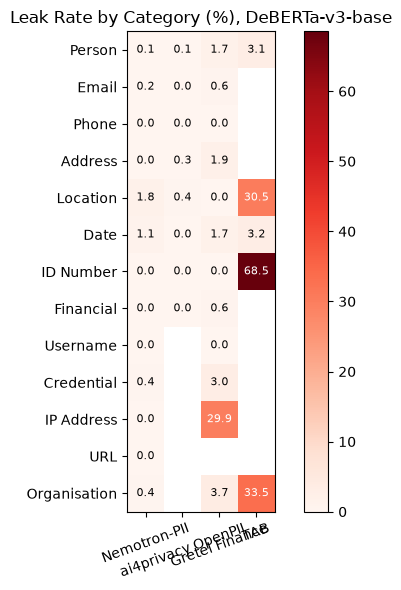

,Nemotron-PII,ai4privacy OpenPII,Gretel Finance,TAB
Person,0.11,0.10,1.74,3.07
Email,0.18,0.00,0.56,NaN
Phone,0.00,0.00,0.00,NaN
Address,0.00,0.26,1.89,NaN
Location,1.75,0.39,0.00,30.50
Date,1.11,0.00,1.73,3.16
ID Number,0.00,0.00,0.00,68.55
Financial,0.00,0.00,0.59,NaN
Username,0.00,NaN,0.00,NaN
Credential,0.35,NaN,2.97,NaN


In [11]:
cat_rows = {}
for name in TEST_SETS:
    _, labels_ = evaluate(name, final_preds[name])
    cat_rows[SET_NAMES[name]] = {CATEGORY_NAMES[l]: (v["leak_rate"] * 100 if v["leak_rate"] is not None else np.nan)
                                 for l, v in labels_.items()}
cat_leak = pd.DataFrame(cat_rows).reindex([CATEGORY_NAMES[l] for l in LABELS])
fig, ax = plt.subplots(figsize=(6.5, 6))
im = ax.imshow(cat_leak.values, cmap="Reds", vmin=0, vmax=max(20, np.nanmax(cat_leak.values)))
ax.set_xticks(range(cat_leak.shape[1]), cat_leak.columns, rotation=20)
ax.set_yticks(range(cat_leak.shape[0]), cat_leak.index)
for i in range(cat_leak.shape[0]):
    for j in range(cat_leak.shape[1]):
        v = cat_leak.values[i, j]
        if v == v:
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8, color="white" if v > 12 else "black")
ax.set_title(f"Leak Rate by Category (%), {ARCH_OF[BEST]}")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig(RESULTS / "fig_category_leak.png", dpi=150)
plt.show()
cat_leak.round(2)

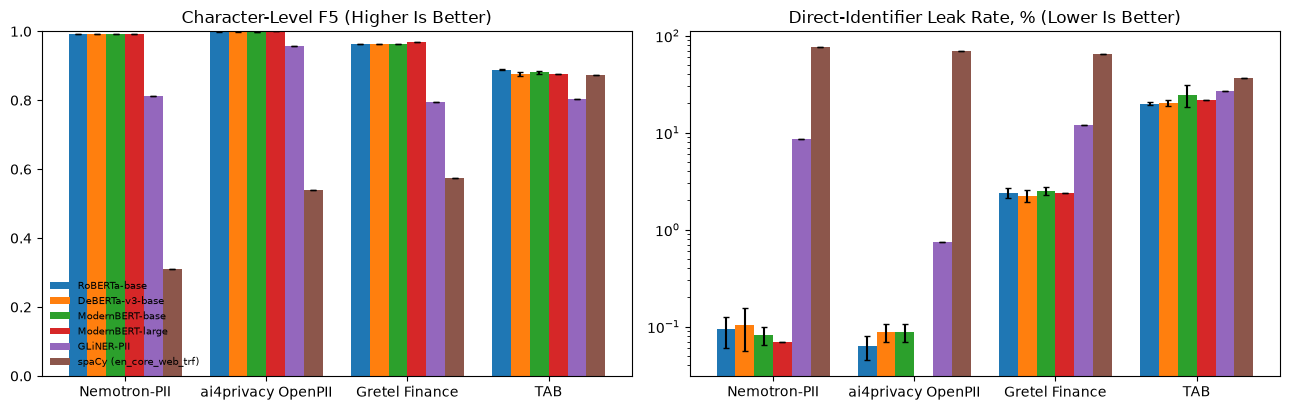

In [12]:
groups = list(RUNS) + [s for s in ("GLiNER-PII", "spaCy (en_core_web_trf)") if s in set(results.system)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
width = 0.8 / len(groups)
for ax, metric, title, log in ((axes[0], "char_f5", "Character-Level F5 (Higher Is Better)", False),
                               (axes[1], "direct_leak_rate", "Direct-Identifier Leak Rate, % (Lower Is Better)", True)):
    for k, group in enumerate(groups):
        means, sds = [], []
        for name in TEST_SETS:
            df = results[(results.test_set == name) & ((results.architecture == group) & results.run.notna()
                                                       | (results.system == group))]
            vals = df[metric] * (100 if metric.endswith("leak_rate") else 1)
            means.append(vals.mean())
            sds.append(vals.std() if len(vals) > 1 else 0)
        ax.bar(np.arange(len(TEST_SETS)) + k * width - 0.4 + width / 2, means, width, yerr=sds, capsize=2, label=group)
    ax.set_xticks(range(len(TEST_SETS)), [SET_NAMES[n] for n in TEST_SETS])
    ax.set_title(title)
    if log:
        ax.set_yscale("log")
axes[0].set_ylim(0, 1)
axes[0].legend(fontsize=7, frameon=False, loc="lower left")
plt.tight_layout()
plt.savefig(RESULTS / "fig_model_comparison.png", dpi=150)
plt.show()

In [13]:
lat = pd.DataFrame(latency).T.round(1).rename(columns={"ms_per_doc": "Milliseconds per Document",
                                                       "ms_per_1k_chars": "Milliseconds per 1,000 Characters"})
lat.index = [run_name(i) for i in lat.index]
lat.index.name = "Model"
lat

,Milliseconds per Document,"Milliseconds per 1,000 Characters"
Model,,
RoBERTa-base (Seed 42),9.1,9.6
RoBERTa-base (Seed 7),9.2,9.7
DeBERTa-v3-base (Seed 42),20.9,22.0
DeBERTa-v3-base (Seed 7),25.4,26.8
ModernBERT-base (Seed 42),19.8,20.9
ModernBERT-base (Seed 7),41.6,43.8
ModernBERT-large (Seed 42),29.5,31.1
ModernBERT-base (Prototype),20.0,21.1


## 7. Export the Selected Model
The selected checkpoint is exported to `models/redactner-best/` with half-precision (fp16) weights split into
files below 45 MB, so it can be stored in a Git repository. A single tensor larger than that, such as DeBERTa's
embedding matrix for its 128,000-token vocabulary, is stored in byte-level parts that the application joins and
verifies the first time it loads the model. `redactner_meta.json` records the decision thresholds, window
settings, provenance and headline metrics used by the application.

In [14]:
best_dir = MODELS / f"redactner-best{SUFFIX}"
if best_dir.exists():
    shutil.rmtree(best_dir)
export_model = AutoModelForTokenClassification.from_pretrained(MODELS / BEST, dtype=torch.float16)
export_model.save_pretrained(best_dir, max_shard_size="45MB", safe_serialization=True)
AutoTokenizer.from_pretrained(MODELS / BEST).save_pretrained(best_dir)
shutil.copy2(MODELS / BEST / "training_summary.json", best_dir / "training_summary.json")
del export_model
print("Stored in parts:", ", ".join(split_large_files(best_dir)) or "none")
summary = json.loads((MODELS / BEST / "training_summary.json").read_text(encoding="utf-8"))
final_name = f"{SELECTED}, Per-Category τ" if USE_CATEGORY_TAU else f"{SELECTED}, Global τ"
meta = {
    "run_name": BEST, "model_name": summary["model_name"], "threshold": chosen_tau[BEST],
    "category_thresholds": category_tau if USE_CATEGORY_TAU else None,
    "max_len": summary["recipe"]["max_len"], "stride": summary["recipe"]["stride"], "labels": LABELS,
    "selection": f"architecture with the highest mean development char-F{BETA} at tuned thresholds "
                 f"(precision >= {MIN_PRECISION:.2f}); best seed exported",
    "dev": dev_category if USE_CATEGORY_TAU else dev_global,
    "test": {r["test_set"]: {k: r[k] for k in TEST_COLS + (TAB_COLS if r["test_set"] == "test_tab" else [])}
             for r in rows if r["system"] == final_name},
}
(best_dir / META_FILE).write_text(json.dumps(meta, indent=2), encoding="utf-8")
for name in TEST_SETS:  # the exported configuration's predictions, for the error analysis in notebook 04
    save_predictions(PREDICTIONS / "selected" / f"{name}.jsonl", sets[name], final_preds[name])

with open(RESULTS / "metrics.json", "w", encoding="utf-8") as fh:
    json.dump({"chosen_tau": chosen_tau, "category_tau": category_tau, "use_category_tau": USE_CATEGORY_TAU,
               "selected_architecture": BEST_ARCH, "selected_run": BEST, "gliner_threshold": gliner_tau,
               "dev_sweep": sweep_rows, "test": rows, "latency": latency,
               "per_label": {f"{k[0]}|{k[1]}": v for k, v in per_label.items()}},
              fh, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
with open(RESULTS / "results_table.md", "w", encoding="utf-8") as fh:
    fh.write(f"# Evaluation Results\n\nSelected model: **{run_name(BEST)}**, exported with "
             f"{'per-category thresholds' if USE_CATEGORY_TAU else f'τ = {chosen_tau[BEST]}'}.\n\n")
    fh.write("## Development Set (Model Selection)\n\n" + selection_table.to_markdown() + "\n\n")
    fh.write("## Leak Rate, All Categories (%)\n\n" + leak_all.to_markdown() + "\n\n")
    fh.write("## Leak Rate, Direct Identifiers (%)\n\n" + leak_direct.to_markdown() + "\n\n")
    for name in TEST_SETS:
        fh.write(f"## {SET_NAMES[name]} Test Set\n\n" + test_table(name).to_markdown() + "\n\n")
    fh.write("## Leak Rate by Category for the Selected Model (%)\n\n" + cat_leak.round(2).to_markdown() + "\n\n")
    fh.write("## Inference Latency (Nemotron-PII Test Set)\n\n" + lat.to_markdown() + "\n")
print("Saved", best_dir.relative_to(ROOT).as_posix(), "and", (RESULTS / "results_table.md").relative_to(ROOT).as_posix())

Stored in parts: model-00001-of-00005.safetensors


Saved models/redactner-best and results/results_table.md


## 8. End-to-End Demonstration
The sample Word documents are redacted with the exported model, and every XML part of each output is checked
for remaining gold values.

In [15]:
from redactner.docx_engine import find_residuals  # noqa: E402
from redactner.labels import PRESETS  # noqa: E402
from redactner.pipeline import RedactionPipeline, build_detector  # noqa: E402

pipeline = RedactionPipeline(build_detector(best_dir))
for path in sorted((ROOT / "samples").glob("*.docx")):
    if path.stem.endswith("_redacted"):
        continue
    out, report = pipeline.redact_bytes(path.read_bytes(), mode="label")
    out_path = path.with_name(f"{path.stem}_redacted.docx")
    out_path.write_bytes(out)
    gold_path = path.parent / f"{path.stem}.gold.json"
    residual = None
    if gold_path.exists():
        gold = json.loads(gold_path.read_text(encoding="utf-8"))
        # Organisation is not part of the default (strict) preset, so it is not expected to be redacted
        gold_values = [g["value"] for g in gold if g["label"] in PRESETS["strict"]]
        residual = find_residuals(out, gold_values)
    counts = ", ".join(f"{CATEGORY_NAMES.get(k, k)} {v}" for k, v in sorted(report.get("counts_by_label", {}).items()))
    print(f"{path.name}: {counts} | Residual gold values: {'n/a' if residual is None else len(residual)}"
          + (f" ({', '.join(sorted({r['value'] for r in residual}))})" if residual else ""))

sample_cv.docx: Address 2, Date 3, Email 3, Financial 2, ID Number 2, Location 3, Person 8, Phone 2 | Residual gold values: 0


sample_letter.docx: Address 6, Credential 1, Date 3, Email 1, ID Number 1, Location 4, Person 11, Phone 2 | Residual gold values: 0
